<a href="https://colab.research.google.com/github/itsmyhomeee/volatility-forecasting/blob/main/volatility_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Прогнозирование реализованной волатильности: HAR-RV, градиентный бустинг и стекинг

**Автор:** Евгений Макаров · [github.com/itsmyhomeee](https://github.com/itsmyhomeee)

**Задача:** прогноз дневной реализованной волатильности (log-RV) на следующий торговый день для 6 рядов: золото, ОФЗ, USD/RUB, ВТБ (2016–2021 и 2011–2022), биткоин. Опционально — свежие данные ВТБ через API Мосбиржи (MOEX ISS).

**Главный вопрос:** дают ли CatBoost, LightGBM и их стекинг прирост качества **по сравнению с классической эконометрической моделью HAR-RV** (Corsi, 2009) при честной out-of-sample проверке?

### Что изменено по сравнению с первой версией

| Было | Стало | Почему это важно |
|---|---|---|
| `train_test_split(random_state=42)` — случайное разбиение | Хронологическое разбиение: последние 20% — тест; подбор гиперпараметров только на train через `TimeSeriesSplit` | Случайное разбиение во временных рядах «подсматривает в будущее» и завышает метрики |
| Дни с High = Low давали RV = 1e-8 → log-RV ≈ −18 | Такие дни (нет торгов / «застывшие» котировки) удаляются, OHLC проверяется на согласованность | Именно эти выбросы давали MAE ≈ 1.9–2.8 на золоте и долларе |
| Нет эталонной модели | Бейзлайны: наивный прогноз (RV завтра = RV сегодня) и **HAR-RV (OLS)** | Без эталона нельзя сказать, полезен ли ML |
| Только R², MAE, RMSE | + **QLIKE** (стандарт для волатильности), R²_OOS относительно HAR, **тест Диболда–Мариано** | QLIKE устойчив к шуму в прокси волатильности (Patton, 2011) |
| Дубли признаков (`RV_lag5` = `RV_weekly`), лаги сдвинуты на день лишний | Классические HAR-компоненты (d / w / m) + leverage, overnight gap, тренд волатильности, объём, день недели | Корректная спецификация HAR и информативные доп. признаки |
| `StackingRegressor(cv=5)` — перемешанные фолды | Стекинг на out-of-fold прогнозах из `TimeSeriesSplit`, мета-модель — линейная регрессия с неотрицательными весами | Мета-модель обучается только на «прошлом» |
| Новая модель: — | **HAR + бустинг на остатках** | Бустинг доучивает нелинейность поверх сильной линейной базы |
| Один тестовый период | + **walk-forward** проверка на 5 последовательных окнах | Проверка устойчивости результата во времени |
| Выводы написаны заранее и противоречили таблицам | Выводы формируются из фактических результатов | Воспроизводимость и честность |
| Данные только из CSV | + загрузчик **MOEX ISS API** (опционально) | Актуальные данные без ручной выгрузки |

## Оглавление
1. [Данные и загрузка](#1)
2. [Очистка данных](#2)
3. [EDA: свойства волатильности](#3)
4. [Признаки](#4)
5. [Протокол валидации и метрики](#5)
6. [Модели](#6)
7. [Обучение и оценка по всем инструментам](#7)
8. [Сводные результаты](#8)
9. [Walk-forward: устойчивость во времени](#9)
10. [Интерпретация: SHAP](#10)
11. [Выводы](#11)

## 1. Данные и загрузка <a id='1'></a>

Дневные OHLCV-котировки (выгрузки ФИНАМ, хранятся в репозитории [`5-diff.-quotes`](https://github.com/itsmyhomeee/5-diff.-quotes)):

| Ряд | Тикер | Класс актива |
|---|---|---|
| Золото | GLDRUB_TOM | сырьё, защитный актив |
| ОФЗ | SU29007 | гособлигации |
| Доллар | USDRUB | валюта |
| ВТБ | VTBR | акция финсектора |
| Биткоин | XBT/USD | криптовалюта |
| ВТБ 2011–2022 | VTBR | расширенная история для проверки эффекта объёма данных |

Фактические периоды печатаются ниже после загрузки.

In [1]:
!pip install -q catboost lightgbm

In [2]:
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import randint, uniform, loguniform

from catboost import CatBoostRegressor, Pool
from lightgbm import LGBMRegressor

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error
from IPython.display import display, Markdown

SEED = 42
np.random.seed(SEED)
N_ITER = 15          # итераций случайного поиска гиперпараметров на модель
N_CV_SPLITS = 5      # фолдов TimeSeriesSplit внутри train
TEST_FRAC = 0.2      # доля последних наблюдений под тест

pd.set_option('display.float_format', lambda x: f'{x:.4f}')
sns.set_theme(style='whitegrid')

In [3]:
BASE = 'https://raw.githubusercontent.com/itsmyhomeee/5-diff.-quotes/refs/heads/main/'
FILES = {
    'Золото':        'GLDRUB_TOM_1day_05052015_05052021.txt',
    'ОФЗ':           'SU29007%20-%20%D0%9E%D0%A4%D0%97.csv',
    'Доллар':        'USDRUB_220101%20-%20%D0%94%D0%9E%D0%9B%D0%9B%D0%90%D0%A0.csv',
    'ВТБ':           '%D0%92%D0%A2%D0%91_%D0%B0%D0%BE_1day_05052016_05052021.txt',
    'Биткоин':       'XXBTZUSD_220101_260101.csv',
    'ВТБ 2011–2022': 'VTBR_2011_2022.csv',
}


def _parse_dates(s):
    s = s.astype(str).str.strip()
    d = pd.to_datetime(s, format='%Y%m%d', errors='coerce')
    if d.isna().mean() > 0.5:                       # другой формат даты в выгрузке
        d = pd.to_datetime(s, dayfirst=True, errors='coerce')
    return d


def load_finam(url):
    # Читает выгрузку ФИНАМ (разделитель ';' или ',') и приводит к формату date/open/high/low/close/volume
    raw = pd.read_csv(url, sep=None, engine='python')
    raw.columns = [c.strip().strip('<>').upper() for c in raw.columns]
    vol_col = next((c for c in ('VOL', 'VOLUME') if c in raw.columns), None)
    df = pd.DataFrame({
        'date':   _parse_dates(raw['DATE']),
        'open':   pd.to_numeric(raw['OPEN'], errors='coerce'),
        'high':   pd.to_numeric(raw['HIGH'], errors='coerce'),
        'low':    pd.to_numeric(raw['LOW'], errors='coerce'),
        'close':  pd.to_numeric(raw['CLOSE'], errors='coerce'),
        'volume': pd.to_numeric(raw[vol_col], errors='coerce') if vol_col else np.nan,
    })
    return (df.dropna(subset=['date']).sort_values('date')
              .drop_duplicates('date').reset_index(drop=True))


raw_data = {name: load_finam(BASE + f) for name, f in FILES.items()}
for name, df in raw_data.items():
    print(f"{name:<15} {len(df):>5} строк   {df.date.min():%Y-%m-%d} — {df.date.max():%Y-%m-%d}")

Золото           1352 строк   2015-05-05 — 2021-05-06
ОФЗ              1001 строк   2001-02-22 — 2031-10-25
Доллар           1231 строк   2001-01-23 — 2031-12-25
ВТБ              1263 строк   2016-05-05 — 2021-05-06
Биткоин          1463 строк   2001-01-22 — 2031-12-25
ВТБ 2011–2022    3125 строк   2011-01-10 — 2022-12-30


### Опционально: свежие данные через API Мосбиржи (MOEX ISS)

Публичный REST API, ключ не нужен. Ответ приходит страницами по 100 строк — загрузчик проходит их по очереди. Если API недоступен, ячейка просто пропускается, остальной ноутбук от неё не зависит.

> В июле 2024 у ВТБ была обратная консолидация акций (5000:1). Garman–Klass считается по внутридневным соотношениям цен и от сплита не зависит, а скачок доходности в день сплита обнуляется в `make_features` (фильтр |r| > 50%).

In [4]:
import requests

USE_MOEX = True


def load_moex(secid, board='TQBR', start='2014-01-01', till=None):
    # Дневная история торгов акцией с Мосбиржи (MOEX ISS) с постраничной загрузкой
    url = (f'https://iss.moex.com/iss/history/engines/stock/markets/shares/'
           f'boards/{board}/securities/{secid}.json')
    params = {'from': start, 'start': 0, 'iss.meta': 'off',
              'history.columns': 'TRADEDATE,OPEN,LOW,HIGH,CLOSE,VOLUME'}
    if till:
        params['till'] = till
    rows, columns = [], None
    while True:
        resp = requests.get(url, params=params, timeout=30)
        resp.raise_for_status()
        block = resp.json()['history']
        columns = block['columns']
        if not block['data']:
            break
        rows.extend(block['data'])
        params['start'] += len(block['data'])
    df = pd.DataFrame(rows, columns=columns).rename(columns=str.lower)
    df = df.rename(columns={'tradedate': 'date'})
    df['date'] = pd.to_datetime(df['date'])
    df = df.dropna(subset=['open', 'high', 'low', 'close'])   # дни без сделок
    return df[['date', 'open', 'high', 'low', 'close', 'volume']].reset_index(drop=True)


if USE_MOEX:
    try:
        vtb_moex = load_moex('VTBR')
        raw_data['ВТБ 2014–н.в. (MOEX API)'] = vtb_moex
        print(f"MOEX ISS: {len(vtb_moex)} строк, {vtb_moex.date.min():%Y-%m-%d} — {vtb_moex.date.max():%Y-%m-%d}")
    except Exception as e:
        print(f'MOEX ISS недоступен, пропускаем: {e}')

MOEX ISS: 3234 строк, 2014-01-06 — 2026-11-20


## 2. Очистка данных <a id='2'></a>

Проверки:
1. **Неположительные или пропущенные цены** — удаляются.
2. **Несогласованные OHLC** (High ниже Open/Close и т. п.) — High/Low корректируются до max/min из OHLC.
3. **Дни без внутридневного диапазона (High = Low)** — удаляются. В такие дни либо не было торгов, либо котировка «застыла». Оценка Garman–Klass там равна нулю, а log(0) = −∞. В первой версии это значение обрезалось до 1e-8, получалось log-RV ≈ −18. Эти точки на порядок выбивались из распределения и ломали метрики.

In [5]:
def clean_ohlc(df):
    d = df.copy()
    px = ['open', 'high', 'low', 'close']
    bad = d[px].isna().any(axis=1) | (d[px] <= 0).any(axis=1)
    d = d[~bad].copy()
    d['high'] = d[px].max(axis=1)
    d['low'] = d[px].min(axis=1)
    flat = d['high'] <= d['low']
    d = d[~flat].reset_index(drop=True)
    report = {'исходно': len(df), 'плохие цены': int(bad.sum()),
              'High = Low': int(flat.sum()), 'осталось': len(d)}
    return d, report


data, reports = {}, []
for name, df in raw_data.items():
    data[name], rep = clean_ohlc(df)
    reports.append({'Ряд': name, **rep})
display(pd.DataFrame(reports).set_index('Ряд'))

,исходно,плохие цены,High = Low,осталось
Ряд,,,,
Золото,1352,0,180,1172
ОФЗ,1001,0,0,1001
Доллар,1231,0,295,936
ВТБ,1263,0,0,1263
Биткоин,1463,0,0,1463
ВТБ 2011–2022,3125,0,0,3125
ВТБ 2014–н.в. (MOEX API),3234,0,0,3234


## 3. EDA: свойства волатильности <a id='3'></a>

Реализованная волатильность считается по формуле **Garman–Klass** (по дневным OHLC):

$$RV_t = \tfrac12\big[\ln(H_t/L_t)\big]^2 - (2\ln 2 - 1)\big[\ln(C_t/O_t)\big]^2$$

Ниже проверяем два свойства, на которых держится HAR-модель:
- **кластеризация волатильности** — периоды высокой и низкой волатильности чередуются;
- **длинная память** — автокорреляция log-RV убывает медленно, на десятки дней.

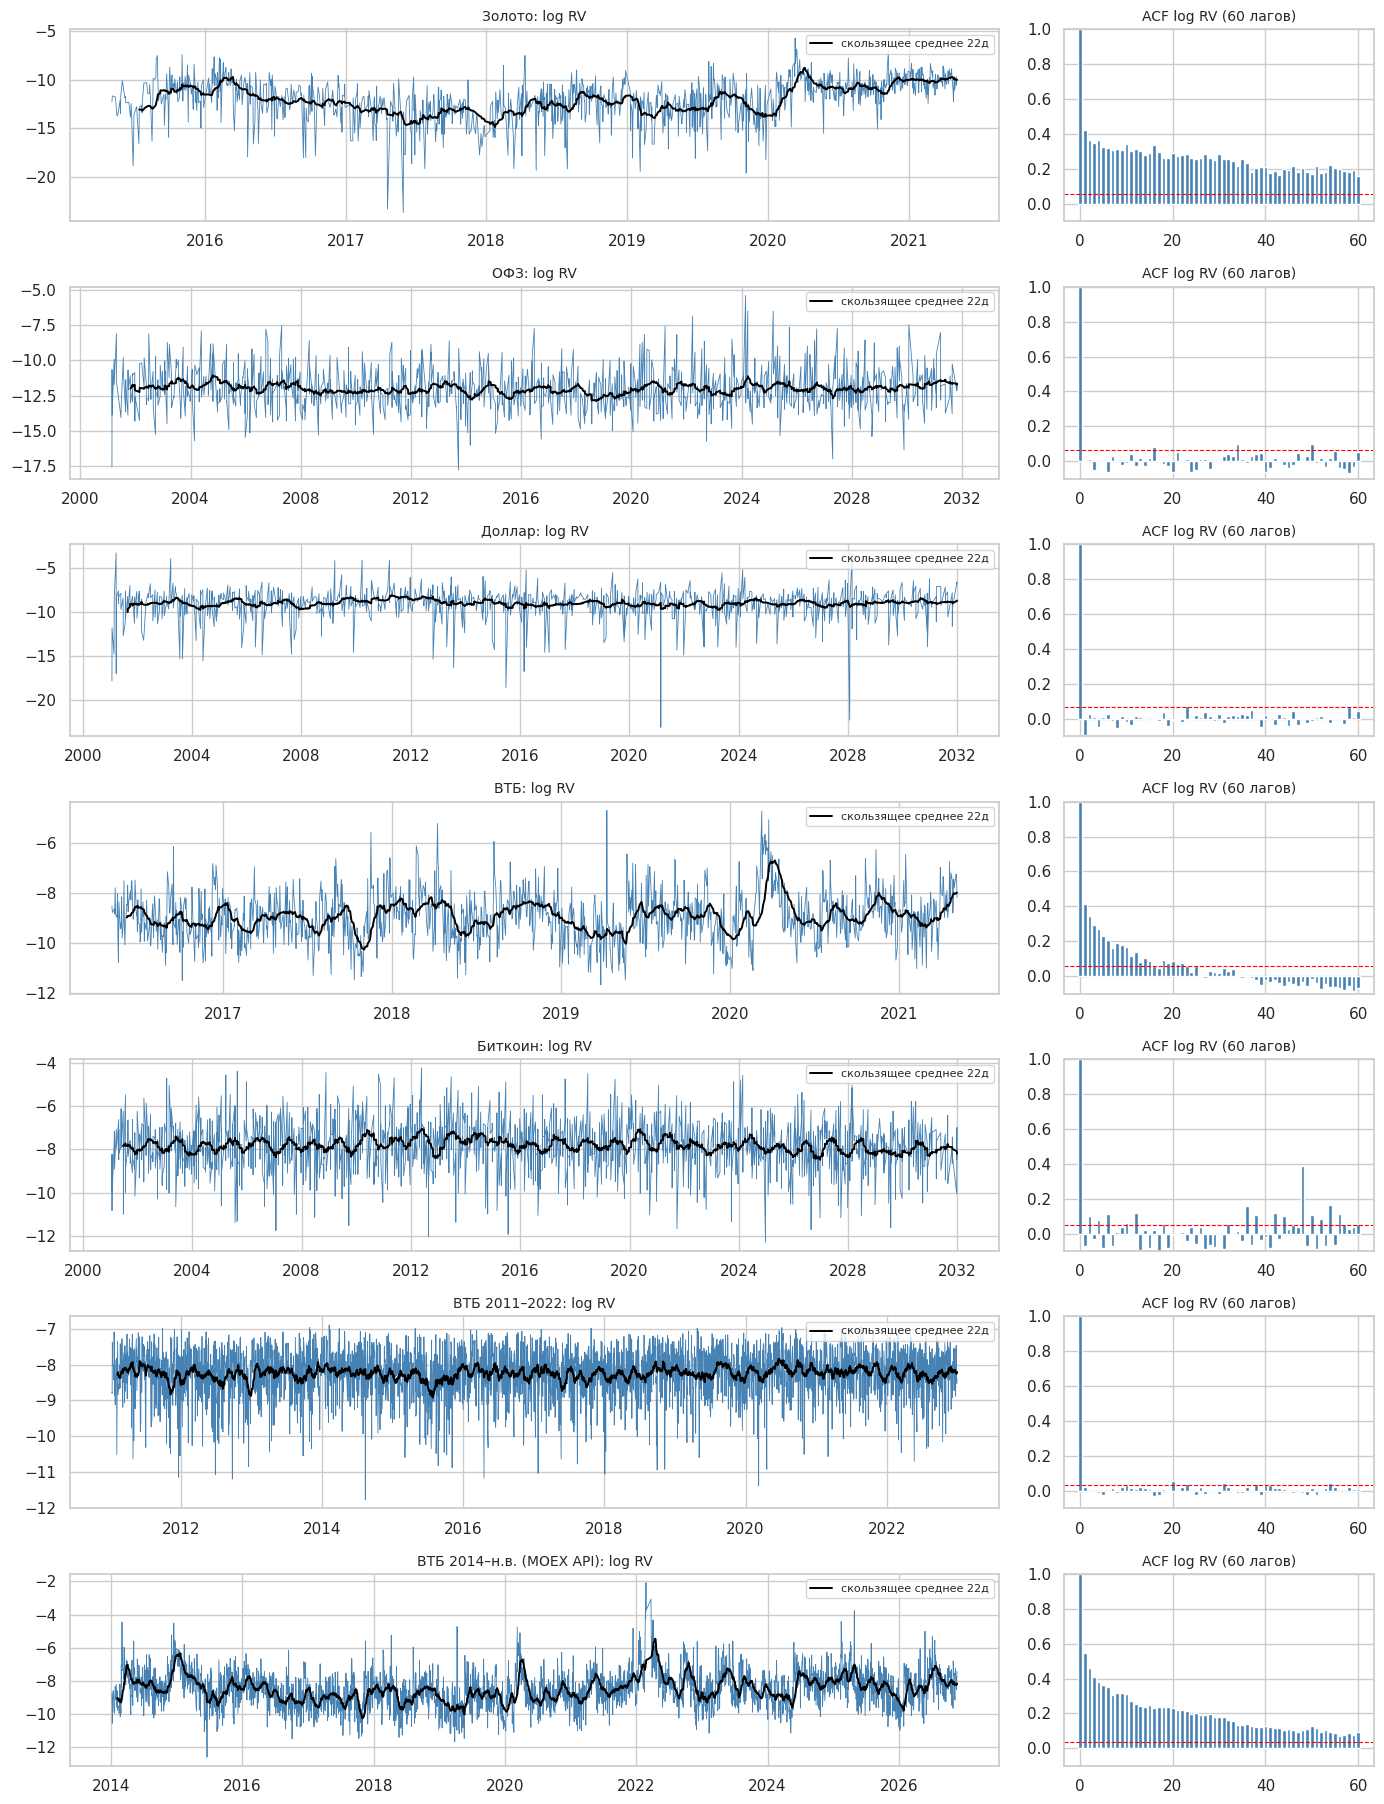

In [6]:
def garman_klass(d):
    hl = np.log(d['high'] / d['low'])
    co = np.log(d['close'] / d['open'])
    return 0.5 * hl ** 2 - (2 * np.log(2) - 1) * co ** 2


def acf(x, nlags=60):
    x = np.asarray(x) - np.mean(x)
    denom = np.sum(x ** 2)
    return np.array([np.sum(x[k:] * x[:len(x) - k]) / denom for k in range(nlags + 1)])


names = list(data)
fig, axes = plt.subplots(len(names), 2, figsize=(14, 2.6 * len(names)),
                         gridspec_kw={'width_ratios': [3, 1]})
for i, name in enumerate(names):
    d = data[name]
    log_rv = np.log(garman_klass(d))
    axes[i, 0].plot(d['date'], log_rv, lw=0.6, color='steelblue')
    axes[i, 0].plot(d['date'], log_rv.rolling(22).mean(), lw=1.4, color='black', label='скользящее среднее 22д')
    axes[i, 0].set_title(f'{name}: log RV', fontsize=10)
    axes[i, 0].legend(loc='upper right', fontsize=8)
    a = acf(log_rv.dropna(), 60)
    axes[i, 1].bar(range(61), a, color='steelblue', width=0.8)
    axes[i, 1].axhline(1.96 / np.sqrt(len(log_rv)), ls='--', color='red', lw=0.8)
    axes[i, 1].set_title('ACF log RV (60 лагов)', fontsize=10)
    axes[i, 1].set_ylim(-0.1, 1)
plt.tight_layout()
plt.show()

In [7]:
desc = []
for name, d in data.items():
    log_rv = np.log(garman_klass(d))
    r = np.log(d['close'] / d['close'].shift(1)).dropna()
    a = acf(log_rv.dropna(), 22)
    desc.append({'Ряд': name, 'N': len(d),
                 'среднее log RV': log_rv.mean(), 'std log RV': log_rv.std(),
                 'асимметрия log RV': stats.skew(log_rv), 'эксцесс доходностей': stats.kurtosis(r),
                 'ACF(1)': a[1], 'ACF(5)': a[5], 'ACF(22)': a[22]})
display(pd.DataFrame(desc).set_index('Ряд'))

,N,среднее log RV,std log RV,асимметрия log RV,эксцесс доходностей,ACF(1),ACF(5),ACF(22)
Ряд,,,,,,,,
Золото,1172,-11.9188,2.1432,-0.8998,6.1476,0.4203,0.3237,0.2788
ОФЗ,1001,-12.0025,1.5413,0.4031,0.4982,-0.0062,0.0001,-0.0003
Доллар,936,-9.0509,1.8342,-2.0864,0.0524,-0.0960,0.0095,-0.0187
ВТБ,1263,-8.9192,1.0103,0.3385,12.3707,0.4158,0.2323,0.0776
Биткоин,1463,-7.8211,1.2081,-0.2670,-0.6724,-0.0724,-0.0832,0.0104
ВТБ 2011–2022,3125,-8.2514,0.7016,-0.8920,-1.1952,0.0242,-0.0221,0.0198
ВТБ 2014–н.в. (MOEX API),3234,-8.4862,1.1070,0.3649,3079.2759,0.5440,0.3645,0.2225


**Что видно:** логарифм RV распределён почти симметрично, поэтому прогнозируем log-RV, а не саму RV. Автокорреляция остаётся значимой на лагах 5 и 22, это аргумент за HAR-структуру (дневной, недельный и месячный компоненты). Распределение доходностей с тяжёлыми хвостами (эксцесс > 0) — типичная картина для финансовых рядов.

## 4. Признаки <a id='4'></a>

Все признаки в строке *t* используют только информацию, доступную **на закрытие дня t**. Цель — $\log RV_{t+1}$.

| Признак | Описание |
|---|---|
| `har_d` | $\log RV_t$ — дневной HAR-компонент |
| `har_w` | среднее $\log RV$ за 5 дней (t−4…t) — недельный |
| `har_m` | среднее $\log RV$ за 22 дня (t−21…t) — месячный |
| `ret`, `neg_ret`, `neg_ret_w` | лог-доходность дня, её отрицательная часть (leverage-эффект) и среднее за неделю |
| `abs_gap` | \|ln(Open_t / Close_{t−1})\| — ночной гэп, который Garman–Klass не учитывает |
| `rv_trend` | `har_w − har_m`: растёт или падает волатильность |
| `rv_std_m` | std log RV за 22 дня — «волатильность волатильности» |
| `log_vol_ratio` | log объёма относительно 22-дневного среднего (если объём есть в данных) |
| `dow` | день недели |

In [8]:
HAR_COLS = ['har_d', 'har_w', 'har_m']
JUMP_THRESHOLD = 0.5   # |лог-доходность| > 50% за день — сплит или ошибка данных


def make_features(df):
    d = df.reset_index(drop=True)
    rv = garman_klass(d)
    log_rv = np.log(rv)
    ret = np.log(d['close'] / d['close'].shift(1))
    gap = np.log(d['open'] / d['close'].shift(1))
    ret = ret.mask(ret.abs() > JUMP_THRESHOLD, 0.0)
    gap = gap.mask(gap.abs() > JUMP_THRESHOLD, 0.0)

    F = pd.DataFrame({'date': d['date']})
    F['har_d'] = log_rv
    F['har_w'] = log_rv.rolling(5).mean()
    F['har_m'] = log_rv.rolling(22).mean()
    F['ret'] = ret
    F['neg_ret'] = ret.clip(upper=0)
    F['neg_ret_w'] = F['neg_ret'].rolling(5).mean()
    F['abs_gap'] = gap.abs()
    F['rv_trend'] = F['har_w'] - F['har_m']
    F['rv_std_m'] = log_rv.rolling(22).std()
    F['dow'] = d['date'].dt.dayofweek
    v = d['volume']
    if v.notna().mean() > 0.95 and (v > 0).mean() > 0.95:
        lv = np.log(v.where(v > 0))
        F['log_vol_ratio'] = lv - lv.rolling(22).mean()

    F['y'] = log_rv.shift(-1)       # цель: log RV завтрашнего дня
    F['rv_next'] = rv.shift(-1)     # та же цель в исходной шкале (для QLIKE)
    return F.dropna().reset_index(drop=True)


def feature_cols(F):
    return [c for c in F.columns if c not in ('date', 'y', 'rv_next')]


features = {name: make_features(d) for name, d in data.items()}
for name, F in features.items():
    print(f"{name:<25} {len(F):>5} наблюдений, {len(feature_cols(F))} признаков")

Золото                     1150 наблюдений, 10 признаков
ОФЗ                         979 наблюдений, 11 признаков
Доллар                      914 наблюдений, 11 признаков
ВТБ                        1241 наблюдений, 11 признаков
Биткоин                    1441 наблюдений, 11 признаков
ВТБ 2011–2022              3103 наблюдений, 11 признаков
ВТБ 2014–н.в. (MOEX API)   3212 наблюдений, 11 признаков


## 5. Протокол валидации и метрики <a id='5'></a>

**Разбиение.** Последние 20% наблюдений каждого ряда — тест. На тест не смотрим до финальной оценки. Гиперпараметры подбираются на train через `TimeSeriesSplit` (5 фолдов, расширяющееся окно): модель всегда обучается на прошлом и проверяется на будущем.

**Метрики** (на тесте):
- **RMSE, MAE** — ошибка прогноза log RV;
- **R²** — доля объяснённой дисперсии log RV на тесте;
- **QLIKE** $= \frac1T\sum\big(\frac{RV_t}{\widehat{RV}_t} - \ln\frac{RV_t}{\widehat{RV}_t} - 1\big)$ — стандартная функция потерь для прогнозов волатильности. Она сильнее штрафует *недооценку* риска и устойчива к шуму в прокси RV. Прогноз переводится из логарифмов с поправкой на смещение: $\widehat{RV} = \exp(\hat y + \tfrac12\hat\sigma^2)$, где $\hat\sigma^2$ — дисперсия out-of-fold остатков на train;
- **ΔRMSE vs HAR** и **ΔQLIKE vs HAR** — улучшение относительно HAR, %;
- **тест Диболда–Мариано** (HAC-дисперсия, Newey–West) — статистически значимо ли модель точнее HAR. p < 0.05 при отрицательной статистике означает, что модель значимо лучше.

In [9]:
def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))


def qlike(rv_true, rv_pred):
    r = np.asarray(rv_true) / np.asarray(rv_pred)
    return float(np.mean(r - np.log(r) - 1))


def score(y_log, pred_log, rv_true, resid_var):
    y_log, pred_log = np.asarray(y_log), np.asarray(pred_log)
    sst = np.sum((y_log - y_log.mean()) ** 2)
    return {
        'RMSE': rmse(y_log, pred_log),
        'MAE': float(mean_absolute_error(y_log, pred_log)),
        'R2': float(1 - np.sum((y_log - pred_log) ** 2) / sst),
        'QLIKE': qlike(rv_true, np.exp(pred_log + 0.5 * resid_var)),
    }


def diebold_mariano(e_model, e_base):
    # DM-тест на квадратичных потерях, HAC-дисперсия (Newey–West). stat < 0 — модель точнее базы
    d = np.asarray(e_model) ** 2 - np.asarray(e_base) ** 2
    T = len(d)
    dc = d - d.mean()
    L = int(np.floor(T ** (1 / 3)))
    lrv = np.sum(dc ** 2) / T
    for k in range(1, L + 1):
        lrv += 2 * (1 - k / (L + 1)) * np.sum(dc[k:] * dc[:-k]) / T
    stat = d.mean() / np.sqrt(lrv / T)
    return float(stat), float(2 * (1 - stats.norm.cdf(abs(stat))))


def time_split(F, test_frac=TEST_FRAC):
    n_test = int(len(F) * test_frac)
    return F.iloc[:-n_test].reset_index(drop=True), F.iloc[-n_test:].reset_index(drop=True)

## 6. Модели <a id='6'></a>

| Модель | Идея |
|---|---|
| **Naive** | $\widehat{\log RV}_{t+1} = \log RV_t$ |
| **HAR-RV** | OLS: $\log RV_{t+1} = \beta_0 + \beta_d\,har_d + \beta_w\,har_w + \beta_m\,har_m$ — эталон из литературы |
| **CatBoost**, **LightGBM** | градиентный бустинг на всех признаках, гиперпараметры подбираются `RandomizedSearchCV` + `TimeSeriesSplit` |
| **HAR + LGBM (остатки)** | сначала HAR, затем LightGBM прогнозирует ошибку HAR по всем признакам. Линейная модель задаёт устойчивую базу, бустинг доучивает нелинейность |
| **Среднее** | простое среднее HAR, CatBoost и LightGBM |
| **Стекинг** | линейная мета-модель с неотрицательными весами поверх out-of-fold прогнозов HAR, CatBoost, LightGBM и HAR+LGBM |

In [10]:
class NaiveRV(BaseEstimator, RegressorMixin):
    def fit(self, X, y):
        return self

    def predict(self, X):
        return X['har_d'].values


class HAR(BaseEstimator, RegressorMixin):
    def __init__(self, cols=tuple(HAR_COLS)):
        self.cols = cols

    def fit(self, X, y):
        self.lr_ = LinearRegression().fit(X[list(self.cols)], y)
        return self

    def predict(self, X):
        return self.lr_.predict(X[list(self.cols)])


class HARPlusBoost(BaseEstimator, RegressorMixin):
    def __init__(self, booster=None, cols=tuple(HAR_COLS)):
        self.booster = booster
        self.cols = cols

    def fit(self, X, y):
        self.har_ = HAR(self.cols).fit(X, y)
        resid = np.asarray(y) - self.har_.predict(X)
        self.boost_ = clone(self.booster).fit(X, resid)
        return self

    def predict(self, X):
        return self.har_.predict(X) + self.boost_.predict(X)


CB_SPACE = {
    'iterations':        randint(200, 800),
    'depth':             randint(2, 6),
    'learning_rate':     loguniform(0.01, 0.1),
    'l2_leaf_reg':       loguniform(1, 30),
    'subsample':         uniform(0.6, 0.4),
    'random_strength':   uniform(0, 2),
}
LGBM_SPACE = {
    'n_estimators':      randint(100, 600),
    'learning_rate':     loguniform(0.01, 0.1),
    'num_leaves':        randint(4, 32),
    'max_depth':         randint(2, 6),
    'min_child_samples': randint(20, 100),
    'subsample':         uniform(0.6, 0.4),
    'colsample_bytree':  uniform(0.5, 0.5),
    'reg_lambda':        loguniform(1e-3, 10),
}


def base_catboost():
    return CatBoostRegressor(loss_function='RMSE', bootstrap_type='Bernoulli',
                             random_seed=SEED, verbose=0, allow_writing_files=False, thread_count=-1)


def base_lgbm():
    return LGBMRegressor(subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1)


def tune(estimator, space, X, y, cv):
    search = RandomizedSearchCV(estimator, space, n_iter=N_ITER, cv=cv,
                                scoring='neg_mean_squared_error',
                                random_state=SEED, n_jobs=1, refit=False)
    search.fit(X, y)
    return clone(estimator).set_params(**search.best_params_), search.best_params_


def oof_predict(model, X, y, cv):
    # Out-of-fold прогнозы на train по TimeSeriesSplit; для первого блока прогноза нет (NaN)
    oof = np.full(len(y), np.nan)
    for tr, va in cv.split(X):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        oof[va] = m.predict(X.iloc[va])
    return oof

## 7. Обучение и оценка по всем инструментам <a id='7'></a>

Для каждого ряда `run_instrument`:
1. делит данные по времени на train и test;
2. подбирает гиперпараметры CatBoost, LightGBM и бустинга на остатках HAR (только на train);
3. строит out-of-fold прогнозы на train — для стекинга и для поправки на смещение в QLIKE;
4. обучает все модели на всём train и оценивает их на тесте.

In [11]:
def run_instrument(name, F, verbose=True):
    t0 = time.time()
    train, test = time_split(F)
    cols = feature_cols(F)
    Xtr, ytr, Xte, yte = train[cols], train['y'], test[cols], test['y']
    cv = TimeSeriesSplit(n_splits=N_CV_SPLITS)

    cb_model, cb_params = tune(base_catboost(), CB_SPACE, Xtr, ytr, cv)
    lgbm_model, lgbm_params = tune(base_lgbm(), LGBM_SPACE, Xtr, ytr, cv)
    har_resid = ytr.values - HAR().fit(Xtr, ytr).predict(Xtr)
    res_booster, _ = tune(base_lgbm(), LGBM_SPACE, Xtr, pd.Series(har_resid), cv)

    models = {
        'Naive':               NaiveRV(),
        'HAR-RV':              HAR(),
        'CatBoost':            cb_model,
        'LightGBM':            lgbm_model,
        'HAR + LGBM (остатки)': HARPlusBoost(booster=res_booster),
    }

    oof, test_pred, fitted = {}, {}, {}
    for m_name, model in models.items():
        oof[m_name] = oof_predict(model, Xtr, ytr, cv)
        fitted[m_name] = clone(model).fit(Xtr, ytr)
        test_pred[m_name] = fitted[m_name].predict(Xte)

    avg_members = ['HAR-RV', 'CatBoost', 'LightGBM']
    oof['Среднее'] = np.mean([oof[m] for m in avg_members], axis=0)
    test_pred['Среднее'] = np.mean([test_pred[m] for m in avg_members], axis=0)

    stack_members = ['HAR-RV', 'CatBoost', 'LightGBM', 'HAR + LGBM (остатки)']
    S_tr = np.column_stack([oof[m] for m in stack_members])
    mask = ~np.isnan(S_tr).any(axis=1)
    meta = LinearRegression(positive=True).fit(S_tr[mask], ytr.values[mask])
    S_te = np.column_stack([test_pred[m] for m in stack_members])
    oof['Стекинг'] = np.where(mask, meta.predict(np.nan_to_num(S_tr)), np.nan)
    test_pred['Стекинг'] = meta.predict(S_te)

    rows = []
    e_har = yte.values - test_pred['HAR-RV']
    for m_name, pred in test_pred.items():
        valid = ~np.isnan(oof[m_name])
        resid_var = np.var(ytr.values[valid] - oof[m_name][valid])
        row = {'Ряд': name, 'Модель': m_name,
               **score(yte, pred, test['rv_next'], resid_var)}
        row['DM stat'], row['DM p-value'] = (np.nan, np.nan) if m_name == 'HAR-RV' \
            else diebold_mariano(yte.values - pred, e_har)
        rows.append(row)
    res = pd.DataFrame(rows)
    har_row = res[res['Модель'] == 'HAR-RV'].iloc[0]
    res['ΔRMSE vs HAR, %'] = 100 * (har_row['RMSE'] - res['RMSE']) / har_row['RMSE']
    res['ΔQLIKE vs HAR, %'] = 100 * (har_row['QLIKE'] - res['QLIKE']) / har_row['QLIKE']

    if verbose:
        best = res[~res['Модель'].isin(['Naive'])].sort_values('RMSE').iloc[0]
        print(f"{name:<25} train={len(train)}, test={len(test)} "
              f"({test['date'].min():%Y-%m-%d} — {test['date'].max():%Y-%m-%d}) | "
              f"лучшая: {best['Модель']} (RMSE {best['RMSE']:.4f}, "
              f"{best['ΔRMSE vs HAR, %']:+.1f}% vs HAR) | {time.time() - t0:.0f}с")

    return {'results': res, 'test': test, 'pred': test_pred, 'fitted': fitted,
            'meta_weights': dict(zip(stack_members, meta.coef_)),
            'params': {'CatBoost': cb_params, 'LightGBM': lgbm_params},
            'cols': cols}


runs = {name: run_instrument(name, F) for name, F in features.items()}

Золото                    train=920, test=230 (2020-06-05 — 2021-05-05) | лучшая: HAR + LGBM (остатки) (RMSE 1.0852, +0.9% vs HAR) | 54с
ОФЗ                       train=784, test=195 (2025-09-24 — 2031-10-24) | лучшая: Среднее (RMSE 1.5471, +0.1% vs HAR) | 39с
Доллар                    train=732, test=182 (2025-08-23 — 2031-12-24) | лучшая: CatBoost (RMSE 1.7619, +0.8% vs HAR) | 37с
ВТБ                       train=993, test=248 (2020-05-12 — 2021-05-05) | лучшая: HAR + LGBM (остатки) (RMSE 0.7980, +1.4% vs HAR) | 41с
Биткоин                   train=1153, test=288 (2025-06-22 — 2031-12-24) | лучшая: HAR + LGBM (остатки) (RMSE 1.1554, +2.2% vs HAR) | 37с
ВТБ 2011–2022             train=2483, test=620 (2020-08-14 — 2022-12-29) | лучшая: HAR-RV (RMSE 0.6649, +0.0% vs HAR) | 65с
ВТБ 2014–н.в. (MOEX API)  train=2570, test=642 (2024-05-08 — 2026-11-19) | лучшая: LightGBM (RMSE 0.8632, +3.2% vs HAR) | 61с


## 8. Сводные результаты <a id='8'></a>

In [12]:
results = pd.concat([r['results'] for r in runs.values()], ignore_index=True)
MODEL_ORDER = ['Naive', 'HAR-RV', 'CatBoost', 'LightGBM', 'HAR + LGBM (остатки)', 'Среднее', 'Стекинг']

for metric in ['RMSE', 'QLIKE', 'R2']:
    tbl = results.pivot(index='Ряд', columns='Модель', values=metric)[MODEL_ORDER].loc[list(runs)]
    best_fn = 'idxmax' if metric == 'R2' else 'idxmin'
    print(f"\n{metric} на тесте (жирным — лучшая модель в строке)")
    styler = tbl.style.format('{:.4f}')
    styler = styler.highlight_max(axis=1, props='font-weight:bold') if metric == 'R2' \
        else styler.highlight_min(axis=1, props='font-weight:bold')
    display(styler)


RMSE на тесте (жирным — лучшая модель в строке)


Модель,Naive,HAR-RV,CatBoost,LightGBM,HAR + LGBM (остатки),Среднее,Стекинг
Ряд,,,,,,,
Золото,1.3968,1.0954,1.1155,1.1264,1.0852,1.0980,1.2694
ОФЗ,2.2612,1.5479,1.5490,1.5536,1.5553,1.5471,1.5507
Доллар,2.7551,1.7757,1.7619,1.7939,1.7975,1.7723,1.7845
ВТБ,1.0096,0.8090,0.8026,0.8077,0.7980,0.8000,0.8112
Биткоин,1.7365,1.1808,1.1563,1.1589,1.1554,1.1630,1.1769
ВТБ 2011–2022,0.9048,0.6649,0.6695,0.6690,0.6690,0.6673,0.6657
ВТБ 2014–н.в. (MOEX API),1.0741,0.8916,0.8662,0.8632,0.8704,0.8667,0.8713



QLIKE на тесте (жирным — лучшая модель в строке)


Модель,Naive,HAR-RV,CatBoost,LightGBM,HAR + LGBM (остатки),Среднее,Стекинг
Ряд,,,,,,,
Золото,2.2922,1.0130,1.1413,1.1758,1.0692,1.0732,0.7577
ОФЗ,2.2032,1.3961,1.4086,1.3847,1.3848,1.3929,1.4207
Доллар,120.1234,1.2537,1.1865,1.1536,1.1957,1.1894,1.1705
ВТБ,0.5358,0.3479,0.3518,0.3596,0.3465,0.3477,0.3629
Биткоин,1.5521,0.6926,0.6598,0.6708,0.6806,0.6706,0.6849
ВТБ 2011–2022,0.4066,0.1886,0.1912,0.1915,0.1916,0.1901,0.1890
ВТБ 2014–н.в. (MOEX API),0.7041,0.4902,0.4737,0.4762,0.4818,0.4745,0.4841



R2 на тесте (жирным — лучшая модель в строке)


Модель,Naive,HAR-RV,CatBoost,LightGBM,HAR + LGBM (остатки),Среднее,Стекинг
Ряд,,,,,,,
Золото,-0.5704,0.0344,-0.0016,-0.0212,0.0522,0.0297,-0.2969
ОФЗ,-1.1430,-0.0043,-0.0057,-0.0116,-0.0139,-0.0032,-0.0079
Доллар,-1.3652,0.0175,0.0327,-0.0027,-0.0068,0.0212,0.0077
ВТБ,-0.3374,0.1413,0.1547,0.1440,0.1645,0.1601,0.1365
Биткоин,-1.2573,-0.0437,-0.0008,-0.0054,0.0008,-0.0125,-0.0368
ВТБ 2011–2022,-0.8566,-0.0026,-0.0165,-0.0150,-0.0149,-0.0098,-0.0051
ВТБ 2014–н.в. (MOEX API),-0.1222,0.2267,0.2700,0.2752,0.2630,0.2692,0.2615


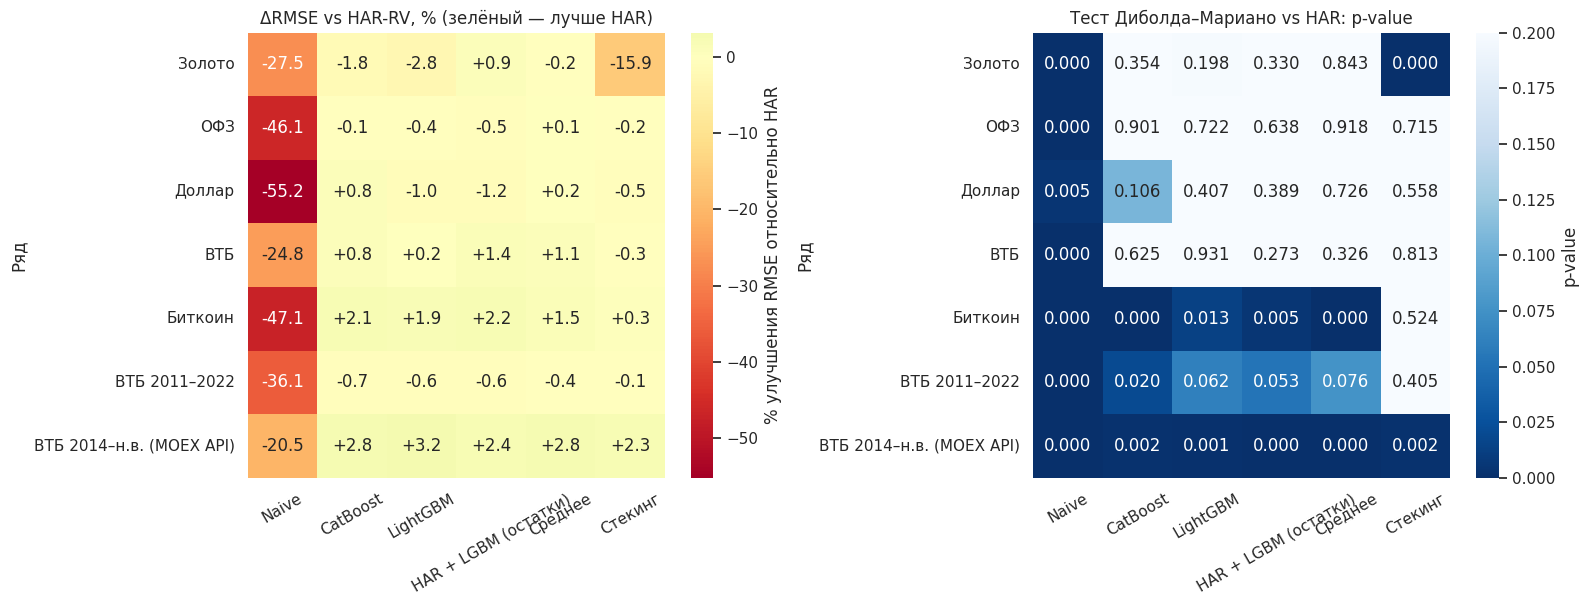

In [13]:
gain = results.pivot(index='Ряд', columns='Модель', values='ΔRMSE vs HAR, %')[MODEL_ORDER].loc[list(runs)]
pval = results.pivot(index='Ряд', columns='Модель', values='DM p-value')[MODEL_ORDER].loc[list(runs)]

fig, axes = plt.subplots(1, 2, figsize=(16, 0.6 * len(runs) + 2))
sns.heatmap(gain.drop(columns='HAR-RV'), annot=True, fmt='+.1f', center=0, cmap='RdYlGn',
            cbar_kws={'label': '% улучшения RMSE относительно HAR'}, ax=axes[0])
axes[0].set_title('ΔRMSE vs HAR-RV, % (зелёный — лучше HAR)')
sns.heatmap(pval.drop(columns='HAR-RV'), annot=True, fmt='.3f', cmap='Blues_r', vmin=0, vmax=0.2,
            cbar_kws={'label': 'p-value'}, ax=axes[1])
axes[1].set_title('Тест Диболда–Мариано vs HAR: p-value')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [14]:
print('Веса мета-модели стекинга (неотрицательные):')
display(pd.DataFrame({n: r['meta_weights'] for n, r in runs.items()}).T)

Веса мета-модели стекинга (неотрицательные):


,HAR-RV,CatBoost,LightGBM,HAR + LGBM (остатки)
Золото,0.0000,0.0000,0.0000,0.8078
ОФЗ,0.0000,0.0000,0.4495,0.0130
Доллар,0.0000,0.0000,0.5935,0.0000
ВТБ,0.4718,0.0445,0.1376,0.6132
Биткоин,0.0000,0.7826,0.0000,0.0000
ВТБ 2011–2022,0.0000,0.0437,0.0000,0.1331
ВТБ 2014–н.в. (MOEX API),0.0000,0.2770,0.0131,0.7502


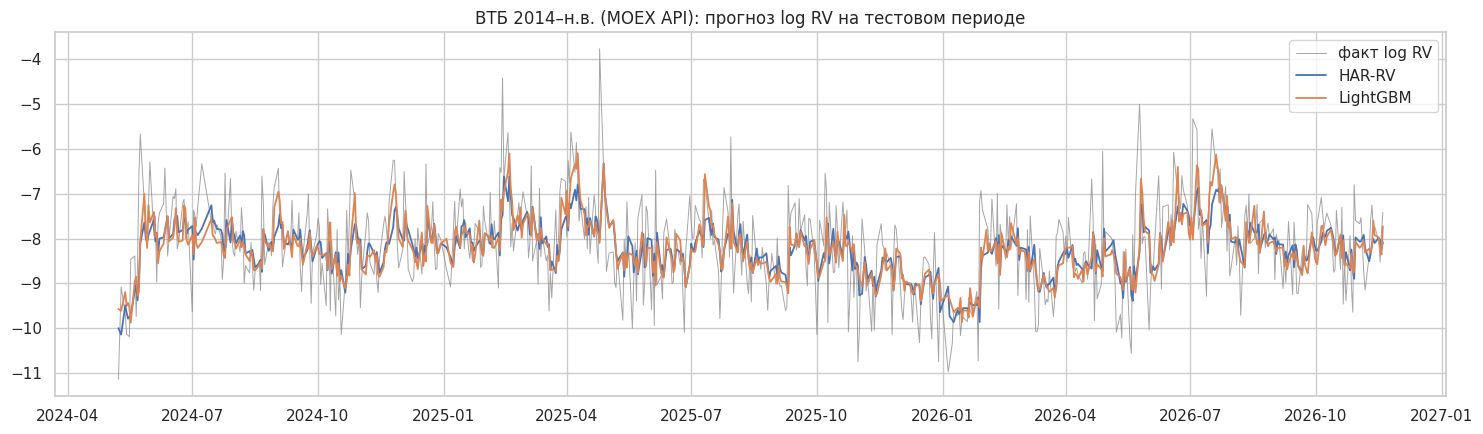

In [15]:
focus = max(runs, key=lambda n: len(features[n]))
r = runs[focus]
best_ml = (r['results'][~r['results']['Модель'].isin(['Naive', 'HAR-RV'])]
           .sort_values('RMSE').iloc[0]['Модель'])

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(r['test']['date'], r['test']['y'], lw=0.7, color='gray', alpha=0.7, label='факт log RV')
ax.plot(r['test']['date'], r['pred']['HAR-RV'], lw=1.3, label='HAR-RV')
ax.plot(r['test']['date'], r['pred'][best_ml], lw=1.3, label=best_ml)
ax.set_title(f'{focus}: прогноз log RV на тестовом периоде')
ax.legend()
plt.tight_layout()
plt.show()

## 9. Walk-forward: устойчивость во времени <a id='9'></a>

Один тестовый период может оказаться удачным или неудачным случайно. Поэтому на самом длинном ряду делаем 5 последовательных шагов: модель обучается на всей истории до окна и прогнозирует следующее окно (~8% данных). Гиперпараметры бустингов берутся из основного запуска, без перенастройки.

In [16]:
F = features[focus]
cols = feature_cols(F)
X, y = F[cols], F['y']
wf = TimeSeriesSplit(n_splits=5, test_size=int(0.08 * len(F)))
fitted = runs[focus]['fitted']
wf_models = {m: fitted[m] for m in ['HAR-RV', 'CatBoost', 'LightGBM', 'HAR + LGBM (остатки)']}

wf_rows = []
for k, (tr, te) in enumerate(wf.split(X), 1):
    preds = {m: clone(mdl).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te]) for m, mdl in wf_models.items()}
    preds['Среднее'] = np.mean([preds['HAR-RV'], preds['CatBoost'], preds['LightGBM']], axis=0)
    period = f"{F['date'].iloc[te[0]]:%Y-%m} — {F['date'].iloc[te[-1]]:%Y-%m}"
    for m, p in preds.items():
        wf_rows.append({'Окно': f'{k}: {period}', 'Модель': m, 'RMSE': rmse(y.iloc[te], p)})

wf_df = pd.DataFrame(wf_rows)
wf_tbl = wf_df.pivot(index='Окно', columns='Модель', values='RMSE')
display(wf_tbl.style.format('{:.4f}').highlight_min(axis=1, props='font-weight:bold'))

wins = (wf_tbl.drop(columns='HAR-RV').lt(wf_tbl['HAR-RV'], axis=0)).sum()
mean_gain = 100 * (1 - wf_tbl.drop(columns='HAR-RV').div(wf_tbl['HAR-RV'], axis=0)).mean()
display(pd.DataFrame({'окон лучше HAR (из 5)': wins, 'средний ΔRMSE vs HAR, %': mean_gain}))

Модель,CatBoost,HAR + LGBM (остатки),HAR-RV,LightGBM,Среднее
Окно,,,,,
1: 2021-10 — 2022-11,0.8812,0.8576,0.9098,0.9114,0.8904
2: 2022-11 — 2023-11,0.9078,0.9054,0.9163,0.9245,0.9095
3: 2023-11 — 2024-11,0.7774,0.7776,0.7954,0.7785,0.7773
4: 2024-11 — 2025-11,0.9018,0.9103,0.9335,0.8974,0.9040
5: 2025-11 — 2026-11,0.8362,0.8473,0.8767,0.8362,0.8430


,окон лучше HAR (из 5),"средний ΔRMSE vs HAR, %"
Модель,,
CatBoost,5,2.8730
HAR + LGBM (остатки),5,3.0005
LightGBM,3,1.9115
Среднее,5,2.4344


## 10. Интерпретация: SHAP <a id='10'></a>

SHAP-значения CatBoost (встроенная реализация, без лишних зависимостей) на тестовом периоде самого длинного ряда. Значение показывает, насколько признак сдвигает прогноз log RV относительно среднего.

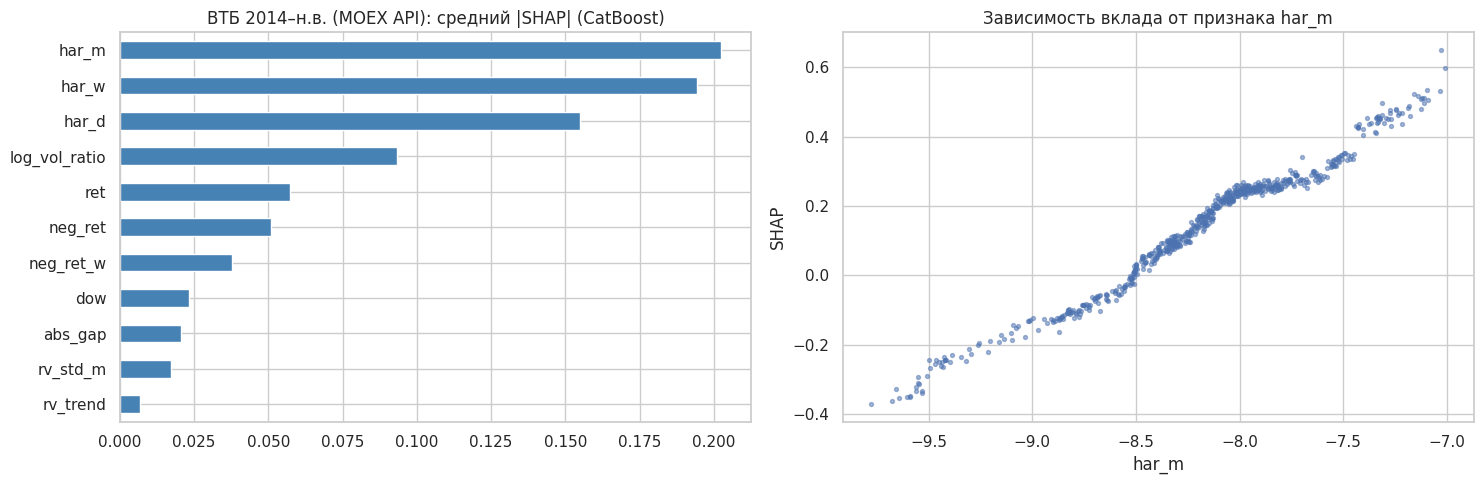

Доля HAR-компонент в суммарном |SHAP|: 64%


In [17]:
cb_fit = runs[focus]['fitted']['CatBoost']
Xte = runs[focus]['test'][runs[focus]['cols']]
shap_vals = cb_fit.get_feature_importance(Pool(Xte), type='ShapValues')[:, :-1]
shap_imp = pd.Series(np.abs(shap_vals).mean(axis=0), index=Xte.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
shap_imp.plot(kind='barh', color='steelblue', ax=axes[0])
axes[0].set_title(f'{focus}: средний |SHAP| (CatBoost)')
top = shap_imp.index[-1]
axes[1].scatter(Xte[top], shap_vals[:, list(Xte.columns).index(top)], s=8, alpha=0.5)
axes[1].set_xlabel(top)
axes[1].set_ylabel('SHAP')
axes[1].set_title(f'Зависимость вклада от признака {top}')
plt.tight_layout()
plt.show()

har_share = shap_imp[HAR_COLS].sum() / shap_imp.sum()
print(f'Доля HAR-компонент в суммарном |SHAP|: {har_share:.0%}')

## 11. Выводы <a id='11'></a>

Выводы ниже формируются из фактических результатов этого запуска.

In [18]:
lines = []
ml_models = ['CatBoost', 'LightGBM', 'HAR + LGBM (остатки)', 'Среднее', 'Стекинг']

har_vs_naive = results[results['Модель'].isin(['Naive', 'HAR-RV'])].pivot(index='Ряд', columns='Модель', values='RMSE')
n_har_better = int((har_vs_naive['HAR-RV'] < har_vs_naive['Naive']).sum())
lines.append(f"1. **HAR-RV — сильный бейзлайн.** Он точнее наивного прогноза на {n_har_better} из {len(runs)} рядов, "
             f"при этом использует всего 4 параметра.")

best_per = (results[results['Модель'].isin(ml_models)]
            .sort_values('RMSE').groupby('Ряд').head(1).set_index('Ряд').loc[list(runs)])
n_beat = int((best_per['ΔRMSE vs HAR, %'] > 0).sum())
n_sig = int(((best_per['ΔRMSE vs HAR, %'] > 0) & (best_per['DM p-value'] < 0.05)).sum())
gains = ', '.join(f"{n}: {row['Модель']} {row['ΔRMSE vs HAR, %']:+.1f}%" for n, row in best_per.iterrows())
lines.append(f"2. **Лучшая ML-модель обыгрывает HAR по RMSE на {n_beat} из {len(runs)} рядов**, "
             f"статистически значимо (DM, p < 0.05) — на {n_sig}. По рядам: {gains}.")

mean_gain_model = (results[results['Модель'].isin(ml_models)]
                   .groupby('Модель')[['ΔRMSE vs HAR, %', 'ΔQLIKE vs HAR, %']].mean()
                   .sort_values('ΔRMSE vs HAR, %', ascending=False))
top_model = mean_gain_model.index[0]
if mean_gain_model.iloc[0, 0] > 0:
    lines.append(f"3. **В среднем по рядам лучше всего работает «{top_model}»**: "
                 f"{mean_gain_model.iloc[0, 0]:+.1f}% по RMSE и {mean_gain_model.iloc[0, 1]:+.1f}% по QLIKE относительно HAR.")
else:
    lines.append(f"3. **В среднем по рядам ни одна ML-модель не обыгрывает HAR.** Ближе всего «{top_model}»: "
                 f"{mean_gain_model.iloc[0, 0]:+.1f}% по RMSE и {mean_gain_model.iloc[0, 1]:+.1f}% по QLIKE. На дневных данных "
                 f"такого объёма почти вся предсказуемость RV уже описывается линейной HAR-структурой.")

stack_vs_best_base = []
for n in runs:
    rr = results[results['Ряд'] == n].set_index('Модель')['RMSE']
    stack_vs_best_base.append(rr['Стекинг'] <= rr[['CatBoost', 'LightGBM']].min())
W = pd.DataFrame({n: r['meta_weights'] for n, r in runs.items()}).T
har_w_share = float((W['HAR-RV'] / W.sum(axis=1).replace(0, np.nan)).mean())
lines.append(f"4. **Стекинг не хуже лучшего отдельного бустинга на {sum(stack_vs_best_base)} из {len(runs)} рядов.** "
             f"В среднем {har_w_share:.0%} веса мета-модели приходится на HAR"
             + (": бустинги в основном корректируют линейный прогноз, а не заменяют его." if har_w_share > 0.5
                else ": мета-модель активно использует нелинейные модели."))

wf_best = mean_gain.idxmax()
lines.append(f"5. **Walk-forward ({focus}):** лучшая по среднему приросту модель — «{wf_best}» "
             f"({mean_gain.max():+.1f}% к HAR, лучше HAR в {int(wins[wf_best])} из 5 окон)"
             + (". Результат устойчив во времени." if wins[wf_best] >= 4 and mean_gain.max() > 0
                else ". Преимущество над HAR нестабильно и зависит от периода."))

lines.append(f"6. **Интерпретация:** на HAR-компоненты приходится {har_share:.0%} суммарного |SHAP| CatBoost, "
             f"главный признак — `{top}`"
             + (". Это согласуется с длинной памятью волатильности." if top in HAR_COLS
                else ". Значит, помимо прошлой волатильности модель использует дополнительную информацию."))

display(Markdown('\n\n'.join(lines)))

1. **HAR-RV — сильный бейзлайн.** Он точнее наивного прогноза на 7 из 7 рядов, при этом использует всего 4 параметра.

2. **Лучшая ML-модель обыгрывает HAR по RMSE на 6 из 7 рядов**, статистически значимо (DM, p < 0.05) — на 2. По рядам: Золото: HAR + LGBM (остатки) +0.9%, ОФЗ: Среднее +0.1%, Доллар: CatBoost +0.8%, ВТБ: HAR + LGBM (остатки) +1.4%, Биткоин: HAR + LGBM (остатки) +2.2%, ВТБ 2011–2022: Стекинг -0.1%, ВТБ 2014–н.в. (MOEX API): LightGBM +3.2%.

3. **В среднем по рядам лучше всего работает «Среднее»**: +0.7% по RMSE и +0.7% по QLIKE относительно HAR.

4. **Стекинг не хуже лучшего отдельного бустинга на 1 из 7 рядов.** В среднем 5% веса мета-модели приходится на HAR: мета-модель активно использует нелинейные модели.

5. **Walk-forward (ВТБ 2014–н.в. (MOEX API)):** лучшая по среднему приросту модель — «HAR + LGBM (остатки)» (+3.0% к HAR, лучше HAR в 5 из 5 окон). Результат устойчив во времени.

6. **Интерпретация:** на HAR-компоненты приходится 64% суммарного |SHAP| CatBoost, главный признак — `har_m`. Это согласуется с длинной памятью волатильности.

### Методологические выводы
- **Протокол валидации важнее выбора модели.** Случайное разбиение и выбросы log-RV ≈ −18 из-за дней без торгов в первой версии искажали метрики сильнее, чем любая разница между CatBoost и LightGBM.
- **ML нужно сравнивать с эконометрическим эталоном.** Сравнение «CatBoost против LightGBM» без HAR ничего не говорит о практической пользе модели.
- **Гибрид «линейная база + бустинг на остатках»** — естественный способ добавить нелинейность, не теряя устойчивости HAR.

### Ограничения
- RV оценивается по дневным OHLC (Garman–Klass). С внутридневными 5-минутными данными оценка RV была бы точнее, а R² — выше.
- Не учитываются внешние факторы: RVI (индекс волатильности Мосбиржи), ключевая ставка ЦБ, нефть, курс рубля для акций.
- Горизонт — один день.

### Развитие
- Добавить внешние признаки через API (MOEX ISS: RVI, индекс IMOEX; ЦБ РФ: ключевая ставка, курсы).
- Горизонты 5 и 22 дня (прямые многошаговые прогнозы).
- Сравнить с GARCH/EGARCH (пакет `arch`) и квантильными прогнозами для VaR.

In [19]:
# Готовая строка для резюме по результатам запуска
mg = mean_gain_model.iloc[0]
head = (f"Прогнозирование реализованной волатильности ({len(runs)} рядов: акции, ОФЗ, валюта, золото, крипто): "
        f"HAR-RV vs CatBoost/LightGBM/стекинг при хронологической валидации (TimeSeriesSplit, walk-forward), метрики RMSE/QLIKE. ")
if mg.iloc[0] > 0:
    tail = (f"Лучшая модель «{top_model}» снизила RMSE на {mg.iloc[0]:.1f}% и QLIKE на {mg.iloc[1]:.1f}% относительно HAR "
            f"(в среднем по рядам); значимое улучшение по тесту Диболда–Мариано — на {n_sig} из {len(runs)} рядов.")
else:
    tail = (f"Показал, что при корректной валидации бустинги не превосходят HAR-RV на дневных данных "
            f"(лучшая ML-модель: {mg.iloc[0]:+.1f}% RMSE к HAR); выявил и устранил утечку из-за случайного разбиения в первой версии.")
print(head + tail)

Прогнозирование реализованной волатильности (7 рядов: акции, ОФЗ, валюта, золото, крипто): HAR-RV vs CatBoost/LightGBM/стекинг при хронологической валидации (TimeSeriesSplit, walk-forward), метрики RMSE/QLIKE. Лучшая модель «Среднее» снизила RMSE на 0.7% и QLIKE на 0.7% относительно HAR (в среднем по рядам); значимое улучшение по тесту Диболда–Мариано — на 2 из 7 рядов.
